<a href="https://colab.research.google.com/github/chupin1986/CMBIA2602/blob/main/AvanceProyecto2_02_imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Preparamos ambiente para poder  importar pandas y usar utilerias para manejo de archivo.

In [6]:
import pandas as pd


Leemos archivo csv con las intenciones  definidas para el entrenamiento del modelo.

In [8]:
df = pd.read_csv("/content/intenciones.csv", encoding='latin-1')
df = df[["texto", "intencion"]].dropna()
df["texto"] = df["texto"].astype(str).str.strip()
df = df[df["texto"] != ""]
print(df.head(10))
print(df["intencion"].value_counts())

            texto intencion
0  Inicia chatbot    inicio
1           vamos    inicio
2           listo    inicio
3       iniciemos    inicio
4      comencemos    inicio
5         iniciar    inicio
6     inicializar    inicio
7        comenzar    inicio
8         empezar    inicio
9          inicio    inicio
intencion
encuesta       47
evaluacion     42
falla          37
transaccion    27
salida         25
registro       23
saludo         22
datos_txn      21
contacto       21
horario        16
inicio         10
Name: count, dtype: int64


Preprocesameinto de las intenciones y entrenamiento del clasificador.

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
  df["texto"], df["intencion"],
  test_size=0.25, random_state=42, stratify=df["intencion"]
)

Normalizacion y representacion del texto.

In [10]:
import re, nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
from sklearn.preprocessing import FunctionTransformer

nltk.download("stopwords")
vacias = set(stopwords.words("spanish")) - {"no", "ni", "nunca"}
raiz = SnowballStemmer("spanish")

def preprocesar(textos):
    return textos.map(lambda s: " ".join(
      raiz.stem(t) for t in re.findall(r"\b\w+\b", str(s).lower())
      if t not in vacias))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Ejemplo de pipeline con TF-IDF y SVM lineal:

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC


modelo_texto = Pipeline([
("limpieza", FunctionTransformer(preprocesar, validate=False)),
("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
("clasificador", LinearSVC(class_weight="balanced"))
])
modelo_texto.fit(X_train, y_train)




Pipeline(steps=[('limpieza',
                 FunctionTransformer(func=<function preprocesar at 0x7e0907f631a0>)),
                ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('clasificador', LinearSVC(class_weight='balanced'))])

Evaluacion del modelo LinearSVC:

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
pred_texto = modelo_texto.predict(X_test)
print(classification_report(y_test, pred_texto, zero_division=0))
print(confusion_matrix(y_test, pred_texto))

              precision    recall  f1-score   support

    contacto       1.00      1.00      1.00         5
   datos_txn       0.83      1.00      0.91         5
    encuesta       0.55      1.00      0.71        12
  evaluacion       1.00      0.55      0.71        11
       falla       1.00      0.89      0.94         9
     horario       1.00      1.00      1.00         4
      inicio       1.00      0.50      0.67         2
    registro       1.00      0.83      0.91         6
      salida       0.83      0.83      0.83         6
      saludo       1.00      0.17      0.29         6
 transaccion       0.78      1.00      0.88         7

    accuracy                           0.81        73
   macro avg       0.91      0.80      0.80        73
weighted avg       0.88      0.81      0.79        73

[[ 5  0  0  0  0  0  0  0  0  0  0]
 [ 0  5  0  0  0  0  0  0  0  0  0]
 [ 0  0 12  0  0  0  0  0  0  0  0]
 [ 0  0  5  6  0  0  0  0  0  0  0]
 [ 0  0  1  0  8  0  0  0  0  0  0]
 [ 0  0

Ahora probaremos con el modelo MultinomialNB:

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB


modelo_texto = Pipeline([
("limpieza", FunctionTransformer(preprocesar, validate=False)),
("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
("clasificador", MultinomialNB())
])
modelo_texto.fit(X_train, y_train)

Pipeline(steps=[('limpieza',
                 FunctionTransformer(func=<function preprocesar at 0x7e0907f631a0>)),
                ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('clasificador', MultinomialNB())])

Evaluación del modelo MultinomialNB:

In [14]:
pred_nb = modelo_texto.predict(X_test)
print(classification_report(y_test, pred_nb, zero_division=0))
print(confusion_matrix(y_test, pred_nb))

              precision    recall  f1-score   support

    contacto       1.00      0.80      0.89         5
   datos_txn       1.00      0.80      0.89         5
    encuesta       0.43      1.00      0.60        12
  evaluacion       0.75      0.55      0.63        11
       falla       0.78      0.78      0.78         9
     horario       1.00      1.00      1.00         4
      inicio       0.00      0.00      0.00         2
    registro       0.83      0.83      0.83         6
      salida       1.00      0.67      0.80         6
      saludo       0.00      0.00      0.00         6
 transaccion       0.83      0.71      0.77         7

    accuracy                           0.70        73
   macro avg       0.69      0.65      0.65        73
weighted avg       0.70      0.70      0.67        73

[[ 4  0  1  0  0  0  0  0  0  0  0]
 [ 0  4  1  0  0  0  0  0  0  0  0]
 [ 0  0 12  0  0  0  0  0  0  0  0]
 [ 0  0  5  6  0  0  0  0  0  0  0]
 [ 0  0  1  0  7  0  0  1  0  0  0]
 [ 0  0

**Como conclusión podemos obtener lo siguiente:**

El modelo LinearSVC fue mejor para nuestro caso, obteniendo un accuracy del 81% comparado con el modelo MultinomialNB de Naive Bayes con un 70% de precisión.

Lo que significa que el modelo LinearSVC se ajusta mas a nuestros casos de uso y puede predecir con mayor exactitud las intenciones de nuestros clientes.

**Vamos a empezar con el procesamiento de imagenes**

Vamos a crear las carpetas atm, pos, e ecommerce en donde podamos depositar las imagenes que utilizaremos en nuestro proyecto.

In [16]:
import os
# Crear la carpeta 'atm' en el entorno de Colab si no existe
os.makedirs('/content/imagenes', exist_ok=True)
os.makedirs('/content/imagenes/pruebas', exist_ok=True)
os.makedirs('/content/imagenes/train', exist_ok=True)
os.makedirs('/content/imagenes/val', exist_ok=True)
os.makedirs('/content/imagenes/test', exist_ok=True)
print("Carpetas: \n '/content/imagenes/train',\n '/content/imagenes/val' \n '/content/imagenes/test' \n '/content/imagenes/pruebas' \nFueron creadas.\n ¡Ya puedes subir las imagenes que usaremos en el modelo")

Carpetas: 
 '/content/imagenes/train',
 '/content/imagenes/val' 
 '/content/imagenes/test' 
 '/content/imagenes/pruebas' 
Fueron creadas.
 ¡Ya puedes subir las imagenes que usaremos en el modelo


Para no renombrar una a una las imagenes manualmente ejecutaremos el siguiente script, solo cambiamos la carpeta y el prefijo.

In [17]:
from pathlib import Path

def renombrar_archivos(ruta_carpeta: str, prefijo: str, inicio: int = 1, digitos: int = 4):
    """
    Renombra todos los archivos de una carpeta con un prefijo y una secuencia numérica.

    :param ruta_carpeta: Ruta de la carpeta que contiene los archivos.
    :param prefijo: Texto inicial para cada archivo (ej. 'atm_ncr').
    :param inicio: Número en el que inicia la secuencia (por defecto 1).
    :param digitos: Cantidad de ceros a la izquierda para el formato (ej. 4 -> 0001).
    """
    # Usamos el parámetro 'ruta_carpeta' en lugar de tener la ruta escrita directamente aquí
    carpeta = Path(ruta_carpeta)

    if not carpeta.is_dir():
        print(f"Error: La ruta '{ruta_carpeta}' no es un directorio válido.")
        return

    # Obtener solo archivos (ignorando subcarpetas) y ordenarlos alfabéticamente
    archivos = sorted([f for f in carpeta.iterdir() if f.is_file()])

    if not archivos:
        print("No se encontraron archivos en la carpeta.")
        return

    contador = inicio
    renombrados = 0

    for archivo in archivos:
        extension = archivo.suffix  # Mantiene la extensión original (.jpg, .png, .pdf, etc.)
        nuevo_nombre = f"{prefijo}_{contador:0{digitos}d}{extension}"
        nueva_ruta = carpeta / nuevo_nombre

        # Evitar sobrescribir si el nombre ya existe
        if nueva_ruta.exists() and nueva_ruta != archivo:
            print(f"Omitido: '{nuevo_nombre}' ya existe.")
            continue

        archivo.rename(nueva_ruta)
        print(f"{archivo.name}  --->  {nuevo_nombre}")

        contador += 1
        renombrados += 1

    print(f"\nProceso finalizado. Total de archivos renombrados: {renombrados}")

# --- Ejemplo de uso ---
if __name__ == "__main__":
    # Usa r"..." en Windows para evitar problemas con las barras invertidas '\'
    RUTA = r"/content/ecommerce"
    PREFIJO = "eco"

    renombrar_archivos(ruta_carpeta=RUTA, prefijo=PREFIJO, inicio=1, digitos=4)

Error: La ruta '/content/ecommerce' no es un directorio válido.


Para descargar la carpeta de imagenes a nuestra maquina local en .zip.

In [ ]:
import shutil
from google.colab import files

# 1. Comprimir la carpeta 'atm' en un archivo zip
print("Comprimiendo archivos, por favor espera...")
shutil.make_archive("imagenes_comp", "zip", "/content/imagenes")

# 2. Descargar el archivo zip a tu máquina local
print("Iniciando descarga de 'imagenes_comp.zip'...")
files.download("imagenes_comp.zip")

Ahora vamos a cargar nuestras imagenes en colab, segmentandolas en train, val y test.

En nuestro caso son 3 categorias una de ATM con 1652 imagenes, otra de POS con 991 imagenes y finalmente otra de Ecommerce con 250 imagenes.

Quedaran distribuidos de la siguiente forma:

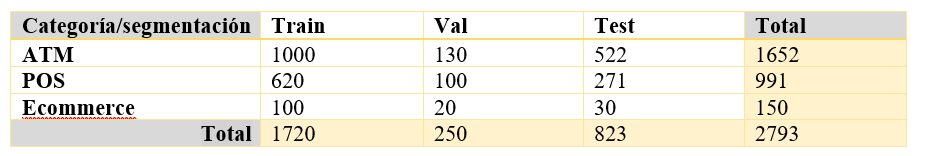


In [21]:
import tensorflow as tf
import os
from pathlib import Path

TAM = (224, 224)
BATCH = 16
RUTA = "/content/imagenes"

# --- ORGANIZAR IMÁGENES EN CARPETAS DE CLASES ---
# Esta sección analiza las carpetas (train, val, test) y crea subcarpetas para cada clase
# (atm, pos, ecommerce) moviendo los archivos de manera correspondiente.
for split in ["train", "val", "test"]:
    split_path = Path(RUTA) / split
    if split_path.is_dir():
        for archivo in split_path.iterdir():
            if archivo.is_file() and archivo.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp", ".avif"]:
                # Determinar la clase según el prefijo del nombre de archivo
                nombre = archivo.name.lower()
                if nombre.startswith("atm"):
                    clase = "atm"
                elif nombre.startswith("pos"):
                    clase = "pos"
                elif nombre.startswith("eco"):
                    clase = "ecommerce"
                else:
                    clase = "otros"

                # Crear la subcarpeta de la clase y mover el archivo allí
                carpeta_clase = split_path / clase
                carpeta_clase.mkdir(exist_ok=True)
                archivo.rename(carpeta_clase / archivo.name)

# --- CARGAR LOS DATASETS ---
train_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/train", image_size=TAM, batch_size=BATCH, seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/val", image_size=TAM, batch_size=BATCH, seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
  RUTA + "/test", image_size=TAM, batch_size=BATCH,
  shuffle=False
)

clases = train_ds.class_names
print("\nClases detectadas:", clases)

Found 1714 files belonging to 3 classes.
Found 249 files belonging to 3 classes.
Found 823 files belonging to 3 classes.

Clases detectadas: ['atm', 'ecommerce', 'pos']


Ahora vamos a entrenar una CNN con nuestros datos cargados con transferencia de aprendizaje.

In [22]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

base = ResNet50(weights="imagenet", include_top=False,
        input_shape=(224, 224, 3))
base.trainable = False


entrada = keras.Input(shape=(224, 224, 3))
x = layers.RandomFlip("horizontal")(entrada)
x = layers.RandomRotation(0.05)(x)
x = preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
salida = layers.Dense(len(clases), activation="softmax")(x)
modelo_img = keras.Model(entrada, salida)


modelo_img.compile(optimizer=keras.optimizers.Adam(1e-3),
  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

Ahora vamos a ejecutar el entrenamiento.

Antes de ejecutar el entrenamiento ejecutaremos validaciones previas de nuestras imagenes cargadas para descartar imagenes corruptas y limpiarlas.
De nuestro train se depuraron 6, quedando 1714/1720, del val se depuró 1 quedadndo 249/250, del test se conservaron las 823 imagenes.

In [ ]:
import os
from pathlib import Path
import tensorflow as tf

# --- LIMPIEZA DE IMÁGENES CORRUPTAS ---
# Este bloque analiza todas las imágenes en el directorio y elimina las que no se pueden decodificar
print("Verificando integridad de las imágenes...")
cantidad_eliminados = 0
for root, dirs, files in os.walk("/content/imagenes"):
    for file in files:
        ruta_archivo = os.path.join(root, file)
        # Solo verificar extensiones comunes de imagen
        if Path(ruta_archivo).suffix.lower() in [".jpg", ".jpeg", ".png", ".webp", ".avif"]:
            try:
                raw = tf.io.read_file(ruta_archivo)
                tf.image.decode_image(raw, channels=3)
            except Exception:
                print(f"Imagen corrupta detectada y eliminada: {ruta_archivo}")
                os.remove(ruta_archivo)
                cantidad_eliminados += 1

if cantidad_eliminados > 0:
    print(f"\nSe eliminaron {cantidad_eliminados} archivos corruptos.")
    print("Por favor, vuelve a ejecutar la celda donde creas `train_ds` y `val_ds` para actualizar los datasets sin los archivos corruptos, y luego corre esta celda de nuevo.")
else:
    print("No se detectaron imágenes corruptas en la estructura actual.")

    # --- ENTRENAMIENTO DEL MODELO ---
    parada = keras.callbacks.EarlyStopping(
      monitor="val_loss", patience=3, restore_best_weights=True)

    historia = modelo_img.fit(
      train_ds, validation_data=val_ds, epochs=15,
      callbacks=[parada]
    )

Verificando integridad de las imágenes...
No se detectaron imágenes corruptas en la estructura actual.
Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 414s 4s/step - accuracy: 0.9457 - loss: 0.1701 - val_accuracy: 0.9960 - val_loss: 0.0125
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 399s 4s/step - accuracy: 0.9942 - loss: 0.0272 - val_accuracy: 0.9960 - val_loss: 0.0138
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 400s 4s/step - accuracy: 0.9971 - loss: 0.0176 - val_accuracy: 0.9960 - val_loss: 0.0069
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 399s 4s/step - accuracy: 1.0000 - loss: 0.0079 - val_accuracy: 0.9960 - val_loss: 0.0119
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 407s 4s/step - accuracy: 0.9959 - loss: 0.0115 - val_accuracy: 0.9960 - val_loss: 0.0059
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 402s 4s/step - accuracy: 0.9994 - loss: 0.0049 - val_accuracy: 0.9960 - val_loss: 0.0083
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 365s 3s/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 0.9960 - val_loss: 0

Evaluaremos nuestro modelo con los datos de test.


In [ ]:
import os
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_real = np.concatenate([y.numpy() for _, y in test_ds])
prob = modelo_img.predict(test_ds)
y_pred = np.argmax(prob, axis=1)
print(classification_report(y_real, y_pred, target_names=clases,
                  zero_division=0))

print(confusion_matrix(y_real, y_pred))

# Crear la carpeta de destino si no existe para evitar el FileNotFoundError
os.makedirs("/content/modelos", exist_ok=True)

#Guardamos el modelo.
modelo_img.save("/content/modelos/clasificador_imagenes.keras")

52/52 ━━━━━━━━━━━━━━━━━━━━ 12s 206ms/step
              precision    recall  f1-score   support

         atm       1.00      1.00      1.00       522
   ecommerce       0.94      0.57      0.71        30
         pos       0.96      1.00      0.98       271

    accuracy                           0.98       823
   macro avg       0.97      0.85      0.89       823
weighted avg       0.98      0.98      0.98       823

[[521   1   0]
 [  1  17  12]
 [  0   0 271]]


Como podemos apreciar en los resultados, nuestro modelo obtuvo un 99% de precisión en las pruebas.
Para las categorias de ATM y POS, acertó en todas las pruebas, solo para la parte de ecommerce solo acertó 23 de 30, falló en 7 imagenes que las clasificó de forma erronea, y tiene sentido debido a que las imagenes para el entrenamiento eran pocas, hace falta agregar mas casos para mejorar la precisión.



**Ahora vamos a hacer la integración multimodal de texto e imagenes**

En este caso, vamos a probar con un texto para identificar intención de falla y posteriormente se verifica el tipo de falla, si es en ATM. POS, o Ecommerce.


In [ ]:
import tensorflow as tf
import numpy as np

# Ruta de una imagen de prueba dentro de tu dataset de pruebas.
ruta_imagen_prueba = "/content/imagenes/pruebas/atm_test1.jpg"
#ruta_imagen_prueba = "/content/imagenes/pruebas/atm_test2.jpg"
#ruta_imagen_prueba = "/content/imagenes/pruebas/pos_test1.jpg"
#ruta_imagen_prueba = "/content/imagenes/pruebas/pos_test2.jpg"
#ruta_imagen_prueba = "/content/imagenes/pruebas/eco_test1.jpg"
#ruta_imagen_prueba = "/content/imagenes/pruebas/eco_test2.jpg"
# Cargamos la imagen y la redimensionamos al tamaño esperado por el modelo (224, 224)
imagen = tf.keras.utils.load_img(ruta_imagen_prueba, target_size=TAM)

# Convertimos la imagen a un array de numpy
imagen_array = tf.keras.utils.img_to_array(imagen)

# Expandimos las dimensiones para simular el lote: de (224, 224, 3) a (1, 224, 224, 3)
imagen_lista = np.expand_dims(imagen_array, axis=0)

print(f"Variable 'imagen_lista' creada con éxito de la ruta: {ruta_imagen_prueba}")
print(f"Forma de la imagen cargada para predicción: {imagen_lista.shape}")

Variable 'imagen_lista' creada con éxito de la ruta: /content/imagenes/pruebas/atm_test1.jpg
Forma de la imagen cargada para predicción: (1, 224, 224, 3)


Visualizamos imagen cargada.

In [5]:
import matplotlib.pyplot as plt

# Como 'imagen_lista' tiene la forma (1, 224, 224, 3), extraemos la primera imagen
# y la convertimos a tipo entero (uint8) para que matplotlib la muestre correctamente
imagen_para_mostrar = imagen_lista[0].astype("uint8")

plt.figure(figsize=(6, 6))
plt.imshow(imagen_para_mostrar)
plt.title(f"Imagen de prueba: {ruta_imagen_prueba.split('/')[-1]}")
plt.axis("off") # Ocultamos los ejes para una mejor visualización
plt.show()

NameError: name 'imagen_lista' is not defined

Identificación de la intención y la  clasificación del canal donde se genera el error:

In [4]:
import pandas as pd
import numpy as np

mensaje = "¿error en pantalla de cajero?"

# Aseguramos la predicción convirtiendo la entrada a una Serie de Pandas
intencion = modelo_texto.predict(pd.Series([mensaje]))[0]

# imagen_lista debe ser un lote con forma (1, 224, 224, 3)
if 'imagen_lista' in globals():
    probabilidades = modelo_img.predict(imagen_lista, verbose=0)[0]
    indice = int(np.argmax(probabilidades))
    etiqueta_imagen = clases[indice]
    confianza = float(probabilidades[indice])

    print("--- RESULTADO DE LA PREDICCIÓN COMBINADA ---")
    print(f"Mensaje de texto: '{mensaje}'")
    print(f"Intención del texto detectada: {intencion}")
    print(f"Clase de la imagen detectada: {etiqueta_imagen} (Confianza: {round(confianza * 100, 2)}%)")
else:
    print(f"Intención de texto detectada: {intencion}")
    print("Nota: No se ejecutó la clasificación de imagen porque 'imagen_lista' no está definida en el entorno actualmente.")

NameError: name 'modelo_texto' is not defined

In [3]:
def responder(intencion, etiqueta, confianza):
  if confianza < 0.60:
    return ("No tengo suficiente certeza para clasificar la imagen. "
      "Prueba con una foto más clara o solicita revisión humana.")

  if intencion == "falla":
      return f"La imagen parece corresponder a {etiqueta_imagen}. "
      "Puedo orientarte sobre la revisión del componente."
  return f"Detecté la intención {intencion} y la clase {etiqueta_imagen}."